# 測定器で電圧を見る(オシロスコープ)

講義で使う**測定器**(Arduino UNO R4 に MimicLab のスケッチを書き込んだもの)のオシロスコープで、いろいろな端子の電圧を見ます。講義の最初の回です。信号発生器と Mimic の使い方は、次の [0-1](01_bypass.ipynb) でやります。

> 準備:[講義の README](../README.md) の結線をして、測定器のスケッチ(MimicLab)を UNO R4 に書き込んでおきます。

## オシロスコープのしくみ

**オシロスコープ**は、電圧が時間とともにどう変わるかをグラフにする測定器です。横軸が時間、縦軸が電圧です。

| | この測定器のオシロ |
|---|---|
| チャンネル | 2 つ。CH1 = A1(結線では Mimic の入力。信号発生器の A0 と同じ列)、CH2 = A2(Mimic の出力 AOUT) |
| 測れる電圧 | 0〜5 V(UNO R4 の ADC、14 bit、1 目盛り約 0.3 mV) |
| 取り込み | 20 kHz(1 秒に 2 万回)で最大 2000 点。2000 点なら 0.1 秒ぶん |

取り込んだ点を PC に送り、Python(matplotlib)でグラフにします。

## 準備:測定器につなぐ

`mimic=` のあとに Mimic のファームのビルド日が出ていれば、Mimic ともつながっています(`none` なら結線を確かめて `lab.mimic.begin()`)。

In [1]:
import matplotlib.pyplot as plt
from mimiclab import MimicLab

lab = MimicLab()  # finds the Arduino; or MimicLab("COM5")
lab

MimicLab(port='COM4', ver=0.1.2, mimic=20261125)

## 実験:取り込んで描く

今の状態のまま、CH1 と CH2 を 0.1 秒ぶん取り込んで、グラフにしてみます。

CH1: mean 2.501 V    CH2: mean 2.500 V


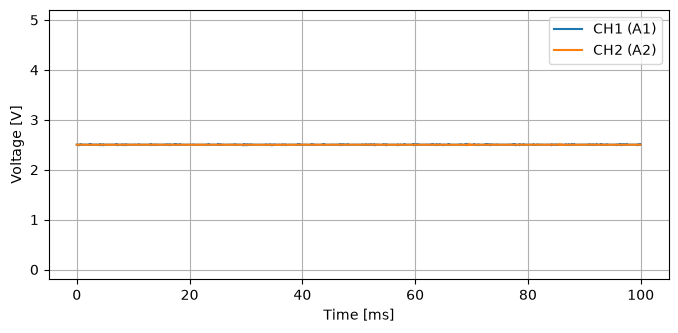

In [2]:
t, ch1, ch2 = lab.scope.capture(2000)   # 2000 points at 20 kHz: 0.1 s
print(f"CH1: mean {ch1.mean():.3f} V    CH2: mean {ch2.mean():.3f} V")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t * 1e3, ch1, label="CH1 (A1)")
ax.plot(t * 1e3, ch2, label="CH2 (A2)")
ax.set_ylim(-0.2, 5.2)
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Voltage [V]")
ax.grid(True)
ax.legend()
plt.show()

何が見えるかは、測定器と Mimic の今の状態によります。測定器を起動したばかりなら、信号発生器は 2.5 V の直流を出しているので、CH1 は 2.5 V 付近の平らな線です。ほかのノートブックで信号を出したあとなら、その波形が見えます。

`t` は時刻(秒)、`ch1` と `ch2` は電圧(V)の数の並び(2000 個ずつ)です。グラフの横軸はミリ秒(ms)にしています。

## やってみよう

ケーブルを付け替えて、いろいろな電圧をオシロで見てみましょう。どこに差すとよいかと、何が見えるはずかは「ヒント」に書いてあります。

> Run All で最後まで実行したあと(接続を閉じたあと)にやるときは、最初の「測定器につなぐ」のセルをもう一度実行してから始めます。

### 1. プローブ(CH1)を付け替える

オシロは、ケーブルの先につながっている**実際の電圧**を測っています。CH1(A1)のケーブルを、オシロの「プローブ」として使ってみましょう。

CH1 のケーブルの**ブレッドボード側**を抜いて、ほかの場所に差し、下のセルを実行します。**差し直すたびに、もう一度実行します**。A0 から Mimic の AIN への線はそのままなので、Mimic には影響しません。

> **注意**
> - 0〜5 V の外の電圧には差さないでください。特に **VIN** は、外から電源をつなぐと 7〜12 V になることがあるので差さないでください。
> - ほかのピンどうしをショートさせないように気をつけてください。
> - 終わったら、**必ず元の列(A0 の列)に戻してください**。戻さないと、ほかの講義で CH1 が Mimic の入力を測れません。
<details><summary>ヒント</summary>

順に差してみましょう。

| 差す先 | 見えるもの |
|---|---|
| Arduino の **3.3V** | 約 3.3 V の平らな線 |
| Arduino の **GND** | 0 V |
| Arduino の **5V** | ほぼ 5 V(目盛りのいちばん上) |
| どこにも差さない(先を宙に浮かせる) | 50 Hz(東日本)か 60 Hz(西日本)の、電源の雑音(ハム)。0.1 秒に山が 5 個か 6 個 |
| 先の金属を**指でつまむ** | ハムに加えて、もっと大きく不規則にふらつく |
| 元の列(A0 の列)に戻す | 信号発生器の出力(測定器を起動したばかりなら 2.5 V の直流) |

何もつながっていない入力は、まわりの電線から交流の雑音(ハム)を拾います。指でつまむと、体が大きなアンテナになり、ハムのほかに静電気やいろいろな雑音も拾うので、さらに大きく不規則にふらつきます。

この ADC は、USB の 5 V を基準(目盛りのいちばん上)にして測っています。USB の電圧が 5 V より低い(例 4.8 V)と、3.3 V が少し高めに読めます。測定器も、自分の基準に対して測っているのです。

</details>

CH1: mean 2.501 V, min 2.487 V, max 2.516 V, peak to peak 28 mV


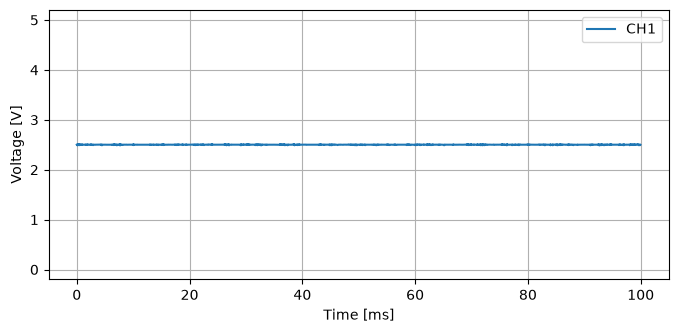

In [3]:
# Move the breadboard end of the CH1 (A1) wire, then run this cell
t, ch1, ch2 = lab.scope.capture(2000)   # 0.1 s
print(f"CH1: mean {ch1.mean():.3f} V, min {ch1.min():.3f} V, max {ch1.max():.3f} V, "
      f"peak to peak {(ch1.max() - ch1.min()) * 1e3:.0f} mV")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t * 1e3, ch1, label="CH1")
ax.set_ylim(-0.2, 5.2)
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Voltage [V]")
ax.grid(True)
ax.legend()
plt.show()

### 2. ずっと見る(ライブ表示)

下のセルを実行すると、取り込みとグラフをくり返して、画面が動き続けます(1 秒に数回)。ケーブルを差し直すと、すぐに画面が変わります。今度は CH1(A1)と CH2(A2)の**両方**を、1 で試した場所にいろいろ差してみましょう。

| ボタン | 働き |
|---|---|
| Free run / Single | くり返して取り込む(はじめはこちら)/ 1 回だけ取り込んで止める(**Capture** でもう 1 回) |
| 0 - 5 V / Auto | 縦軸を 0〜5 V に固定する(はじめはこちら)/ 波形に合わせて広げる |
| Stop | ライブ表示を終わる(最後の画面が残る) |

- グラフの右に、チャンネルごとの**平均の電圧**と**周波数**が出ます。周波数は、0.1 秒に 2 周期以上入る(約 20 Hz より速い)波形のときだけ出ます。直流のときは「-」です。
- 動かしているあいだも、ほかのセルを実行できます。
- CH2 は、A2 から Mimic の AOUT へのケーブルの **AOUT 側**を抜いて差します。

> **注意**
> - 0〜5 V の外の電圧には差さないでください。特に **VIN** には差さないでください。
> - 終わったら、**CH1 は A0 の列に、CH2 は AOUT に戻してください**。

<details><summary>ヒント</summary>

- 先を宙に浮かせると、ハムの周波数(50 Hz か 60 Hz)が読めます。**Auto** にすると、ハムが画面いっぱいに広がって見えます。縦軸の目盛りがどれだけ変わったかを見比べましょう(同じ雑音でも、目盛り次第で大きくも小さくも見えます)。
- 先を指でつまんで、つまむ強さを変えたり、もう片方の手で Arduino の GND に触れたりすると、ふらつき方が変わります。
- CH1 を指でつまんだまま、CH2 を 5V、3.3V、GND と差し替えると、CH1 の平均の電圧が CH2 のほうへ寄っていきます。ADC は 1 回測るたびに、中の小さなコンデンサ(数 pF)をピンにつなぎます。このコンデンサには、直前に測った CH2 の電圧が残っています。1 秒に 2 万回、少しずつ電荷を出し入れするので、指のようにインピーダンスの高い相手では、**測ること自体が電圧を変えてしまいます**。電源やほかの講義の回路(信号発生器や Mimic の出力)のように、インピーダンスの低い相手では、この影響はほとんど見えません。
- CH1 を 5V、CH2 を 3.3V に差すと、2 本の平らな線の差が 1.7 V 程度になります。
- 動かしたまま、別のセルで `lab.fg.sine(100, 1.0)` を実行して、CH1 を A0 の列に戻すと、信号発生器の正弦波(100 Hz)が見えます。

</details>

In [4]:
live = lab.scope.live()   # buttons: Free run / Single, 0 - 5 V / Auto, Stop

## 測定器につなげるのは 1 つのノートブックだけ

測定器(Arduino)のシリアルポートは、1 つのプログラムしか開けません。ノートブックの最後では、必ず `lab.close()` で接続を閉じます。

JupyterLab では、ノートブックのタブを閉じても Python(カーネル)は動き続け、接続もつながったままです。閉じ忘れたまま別のノートブックで `MimicLab()` を実行すると、「ポートを開けません」というエラーになります。そのときは、

- 前のノートブックに戻って `lab.close()` を実行する、または
- JupyterLab の左の「実行中のカーネルとターミナル」から、前のノートブックのカーネルを止める

のどちらかをしてから、もう一度つなぎます。PlatformIO や Arduino IDE のシリアルモニタも閉じておきます。

## まとめ

- オシロスコープは、電圧の時間変化を見る測定器。`lab.scope.capture()` で 1 回取り込み、`lab.scope.live()` でずっと見る。
- 何もつながっていない入力は、まわりの電線から電源のハム(50 Hz か 60 Hz)を拾う。
- 測定器の ADC は、USB の 5 V を基準(目盛りのいちばん上)にして測っている。

最後に接続を閉じます(ライブ表示も止まります)。

In [5]:
lab.close()